# Feature Analysis — Every Column vs the Target

**Target:** `classification` → `ckd` (250, 62.5 %) / `notckd` (150, 37.5 %)

## Plot strategy (target is categorical)

| Condition | Plot | Why |
|---|---|---|

| Few discrete levels (≤ 6), ordinal | **Bar plot** (level counts by target) | The mode is the meaningful summary; box/violin smear an ordinal scale. |

| Continuous, `mean ≈ median`, `|skew| < 0.5 | **Violin plot** | Near‑symmetric, so the full distribution shape can be compared by class. |

| Continuous, `mean ≠ median`, `|skew| ≥ 0.5 | **Box plot** | Median/IQR is robust to skewed tails and outliers. |

| Categorical vs categorical | **Grouped count plots** + **heatmaps** of level‑vs‑target split and Cramér’s V | One view per feature, plus an association matrix. |

## 0. Setup — load and clean

In [1]:
%matplotlib inline
import warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.titlesize"] = 12

DATA_PATH = "kidney_disease.csv"
raw = pd.read_csv(DATA_PATH)
clean = raw.copy()
text_cols = [c for c in clean.columns if not pd.api.types.is_numeric_dtype(clean[c])]
for c in text_cols:
    clean[c] = (clean[c].astype("string")
                .str.replace("\t", "", regex=False).str.strip())
    clean[c] = clean[c].replace({"": pd.NA, "?": pd.NA, "nan": pd.NA})
for c in ["pcv", "wc", "rc"]:
    clean[c] = pd.to_numeric(clean[c], errors="coerce").astype("float64")
clean["classification"] = clean["classification"].map({"ckd": 1, "notckd": 0}).astype("int64")
clean["target"] = clean["classification"].map({0: "notckd", 1: "ckd"})
TARGET = "target"
ORDER = ["notckd", "ckd"]
PALETTE = {"notckd": "#66C2A5", "ckd": "#FC8D62"}
NUM_COLS = ["age","bp","sg","al","su","bgr","bu","sc","sod","pot","hemo","pcv","wc","rc"]
CAT_COLS = ["rbc","pc","pcc","ba","htn","dm","cad","appet","pe","ane"]
PLOT_FOR = {"age":"box","bp":"box","bgr":"box","bu":"box","sc":"box","sod":"box","pot":"box","wc":"box",
            "hemo":"violin","pcv":"violin","rc":"violin","sg":"bar","al":"bar","su":"bar"}
print(f"{clean.shape[0]} rows x {raw.shape[1]} columns (raw); analysis frame: {clean.shape[1]} cols")
print("Target counts:")
print(clean[TARGET].value_counts().reindex(ORDER).to_string())

400 rows x 26 columns (raw); analysis frame: 27 cols
Target counts:
target
notckd    150
ckd       250


## 1. Plot helpers

In [2]:
def plot_box(col):
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.boxplot(data=clean, x=TARGET, y=col, order=ORDER, hue=TARGET, hue_order=ORDER,
                palette=PALETTE, width=0.5, dodge=False, legend=False, ax=ax)
    sns.stripplot(data=clean, x=TARGET, y=col, order=ORDER, color="black",
                  size=2, alpha=0.30, jitter=True, ax=ax)
    ax.set_title(f"{col} by target — box plot"); ax.set_xlabel(""); ax.set_ylabel(col)
    plt.tight_layout(); plt.show()

def plot_violin(col):
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.violinplot(data=clean, x=TARGET, y=col, order=ORDER, hue=TARGET, hue_order=ORDER,
                   palette=PALETTE, cut=0, inner="quartile", dodge=False, legend=False, ax=ax)
    ax.set_title(f"{col} by target — violin plot"); ax.set_xlabel(""); ax.set_ylabel(col)
    plt.tight_layout(); plt.show()

def plot_ordinal_bars(col):
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.countplot(data=clean, x=col, hue=TARGET, hue_order=ORDER, palette=PALETTE, ax=ax)
    ax.set_title(f"{col} level counts by target — bar plot"); ax.set_xlabel(col); ax.set_ylabel("patients")
    plt.tight_layout(); plt.show()

def plot_count(col):
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.countplot(data=clean, x=col, hue=TARGET, hue_order=ORDER, palette=PALETTE, ax=ax)
    ax.set_title(f"{col} by target — count plot"); ax.set_xlabel(col); ax.set_ylabel("patients")
    plt.tight_layout(); plt.show()

def cramers_v(a, b):
    df = pd.DataFrame({"a": a, "b": b}).dropna()
    ct = pd.crosstab(df["a"], df["b"])
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return np.nan
    observed = ct.to_numpy(); n = observed.sum()
    expected = np.outer(observed.sum(axis=1), observed.sum(axis=0)) / n
    with np.errstate(divide="ignore", invalid="ignore"):
        chi2 = np.nansum((observed - expected) ** 2 / expected)
    r, k = observed.shape
    return float(np.sqrt(chi2 / (n * (min(r, k) - 1))))

## 2. Numeric features vs target

### `age` (numeric) vs `classification` — box plot

mean 51.5 < median 55 < mode 60 → left‑skewed; box keeps median/IQR.

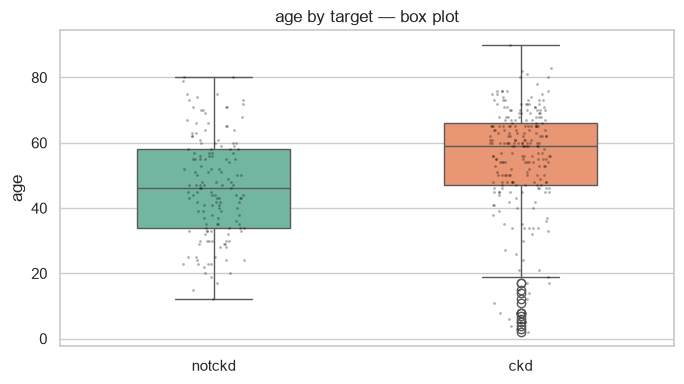

In [3]:
plot_box("age")

### `bp` (numeric) vs `classification` — box plot

median 80 vs 70 mmHg; right‑tail outliers → box + dots.

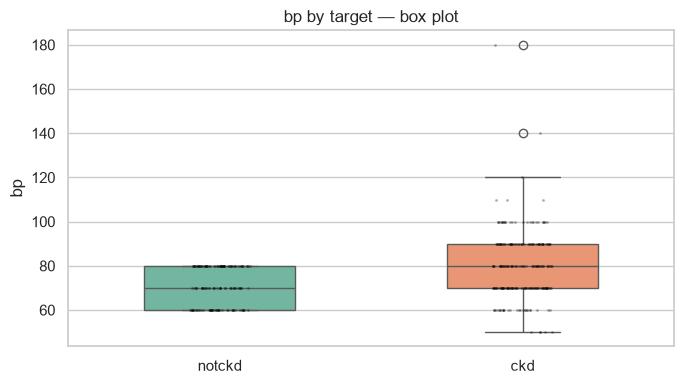

In [4]:
plot_box("bp")

### `sg` (numeric) vs `classification` — bar plot

only 5 discrete levels; mode 1.02; bar preserves ordinal levels.

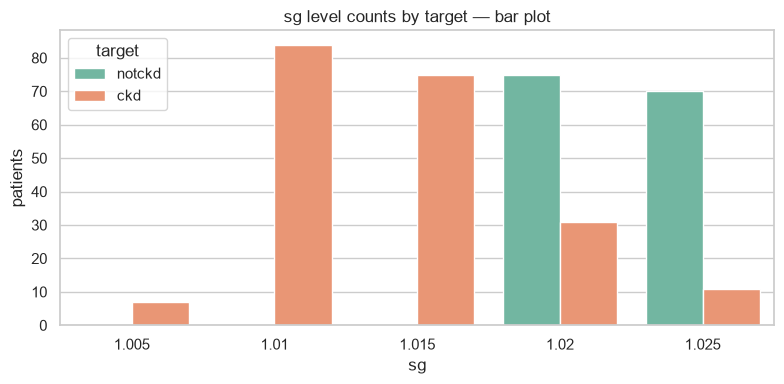

In [5]:
plot_ordinal_bars("sg")

### `al` (numeric) vs `classification` — bar plot

ordinal 0–5, zero‑inflated; per‑grade counts beat a single mean.

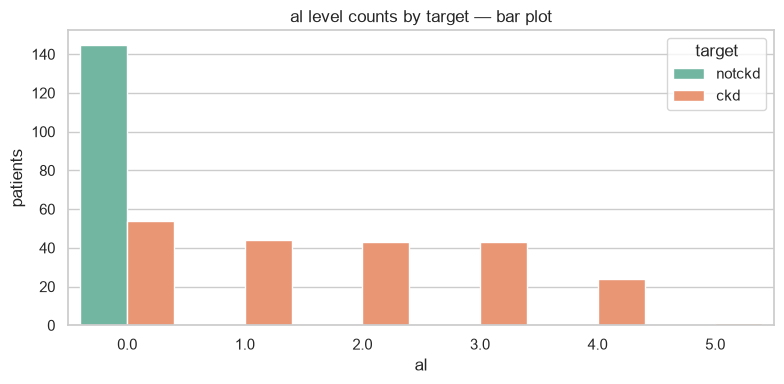

In [6]:
plot_ordinal_bars("al")

### `su` (numeric) vs `classification` — bar plot

median/mode 0 for both classes; mean 0.77 vs 0 only shows in bars.

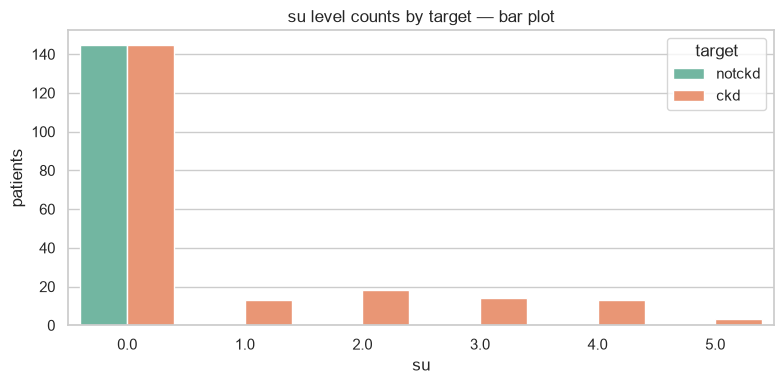

In [7]:
plot_ordinal_bars("su")

### `bgr` (numeric) vs `classification` — box plot

mean 175 vs 108, skew +2.0 → box/median robust.

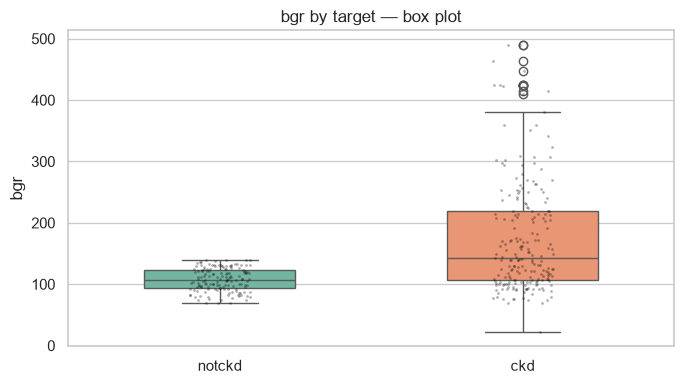

In [8]:
plot_box("bgr")

### `bu` (numeric) vs `classification` — box plot

median 53 vs 33, skew +2.6 → box isolates extremes.

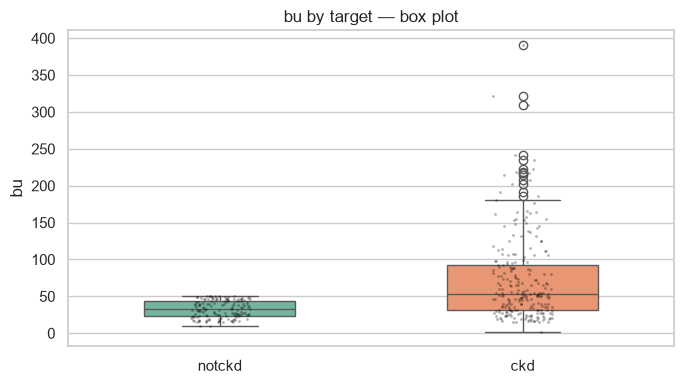

In [9]:
plot_box("bu")

### `sc` (numeric) vs `classification` — box plot

median 2.25 vs 0.90, skew +7.5 → median/IQR the honest comparison.

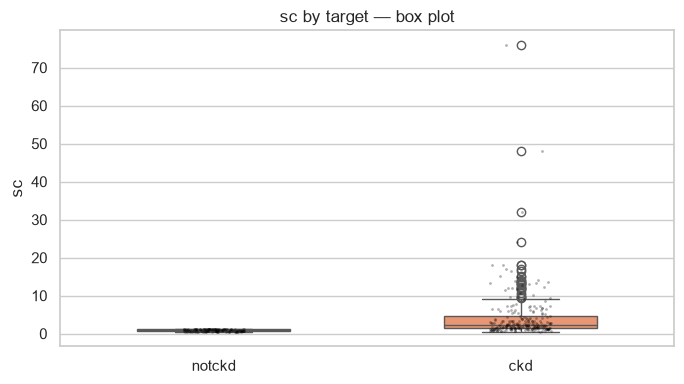

In [10]:
plot_box("sc")

### `sod` (numeric) vs `classification` — box plot

median 136 vs 141; `4.5` typo appears as low outlier; box robust.

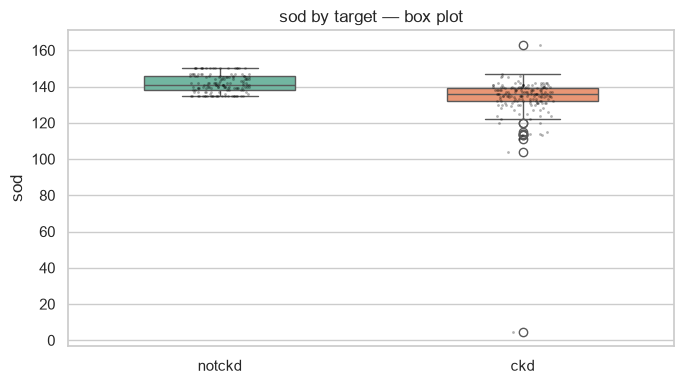

In [11]:
plot_box("sod")

### `pot` (numeric) vs `classification` — box plot

median 4.3 vs 4.5, mean 4.88 vs 4.34; `47` typo appears as outlier; box robust.

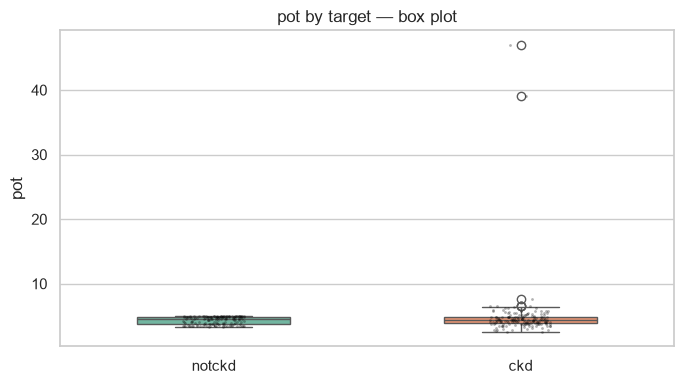

In [12]:
plot_box("pot")

### `hemo` (numeric) vs `classification` — violin plot

mean ≈ median, |skew| < 0.5 → violin shows level shift + shape.

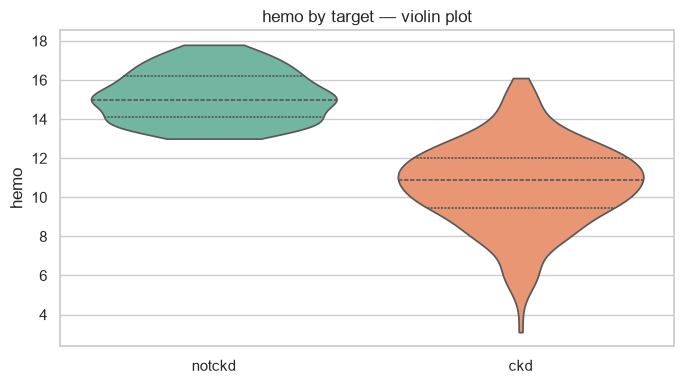

In [13]:
plot_violin("hemo")

### `pcv` (numeric) vs `classification` — violin plot

near‑symmetric (mean 38.9 ≈ median 40, skew −0.4) → violin compares distributions.

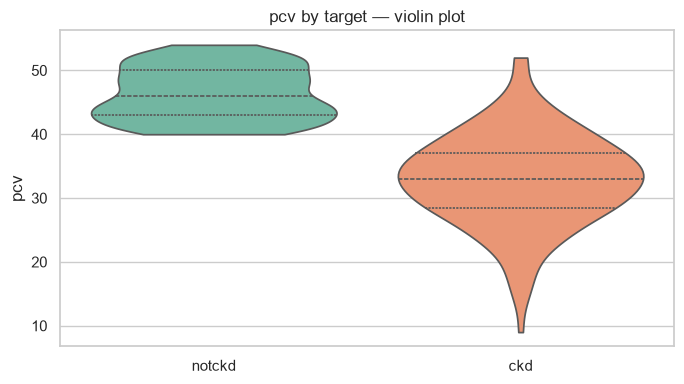

In [14]:
plot_violin("pcv")

### `rc` (numeric) vs `classification` — violin plot

symmetric (mean 4.71 ≈ median 4.80, skew −0.2) → violin; note multicollinearity with hemo/pcv.

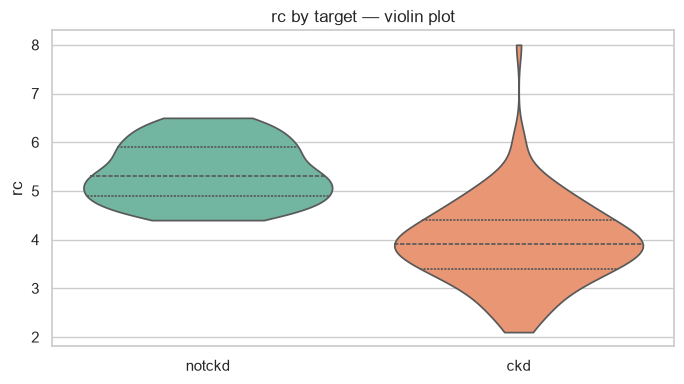

In [15]:
plot_violin("rc")

### `wc` (numeric) vs `classification` — box plot

mean 9070 vs 7706, skew +1.6 → box keeps median meaningful against tail.

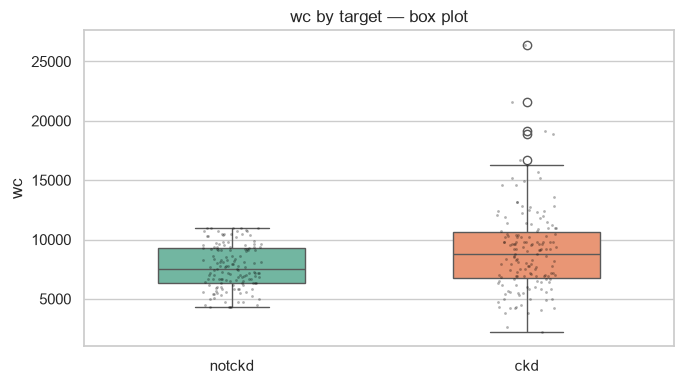

In [16]:
plot_box("wc")

### `id` (identifier) vs `classification` — box plot

**What the plot says:** the two classes have identical distributions of `id`; it is just a sequential row number (0–399).

**Why a box plot:** it is the quickest way to confirm the null — `id` carries no clinical signal and should be **dropped** before modeling.

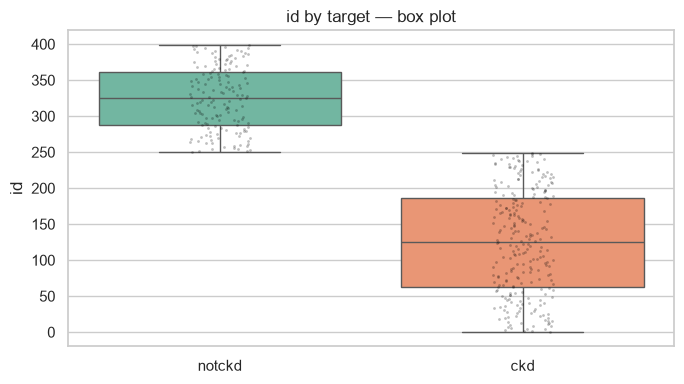

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=clean, x=TARGET, y="id", order=ORDER, hue=TARGET, hue_order=ORDER,
            palette=PALETTE, dodge=False, legend=False, ax=ax)
sns.stripplot(data=clean, x=TARGET, y="id", order=ORDER, color="black",
              size=2, alpha=0.25, jitter=True, ax=ax)
ax.set_title("id by target — box plot"); ax.set_xlabel(""); ax.set_ylabel("id")
plt.tight_layout(); plt.show()

### `classification` (target) — class balance

**What the plot says:** **250 CKD (62.5 %)** vs **150 not‑CKD (37.5 %)** — moderately imbalanced.

**Why a count plot:** the target is categorical, so its own distribution is best shown as counts; the imbalance means we should use a stratified split and class weights / resampling.

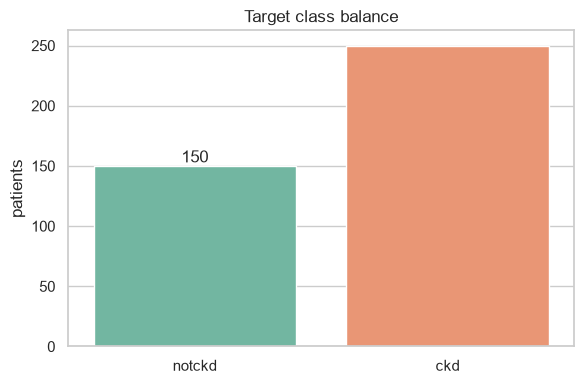

target
notckd    37.5
ckd       62.5


In [18]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=clean, x=TARGET, order=ORDER, hue=TARGET, hue_order=ORDER,
              palette=PALETTE, legend=False, ax=ax)
ax.bar_label(ax.containers[0])
ax.set_title("Target class balance"); ax.set_xlabel(""); ax.set_ylabel("patients")
plt.tight_layout(); plt.show()
print(clean[TARGET].value_counts(normalize=True).reindex(ORDER).mul(100).round(1).to_string())

## 3. Categorical features vs target

### `rbc` (categorical) vs `classification` — count plot

**What the plot says:** all **47 `abnormal` RBC cases are CKD (100 %)**, while `normal` is 70% not‑CKD. **38 % missing**.

**Why a count plot:** binary categorical vs categorical → grouped counts expose the class split; the missingness is target‑related (MNAR), so keep an `rbc_was_missing` flag.

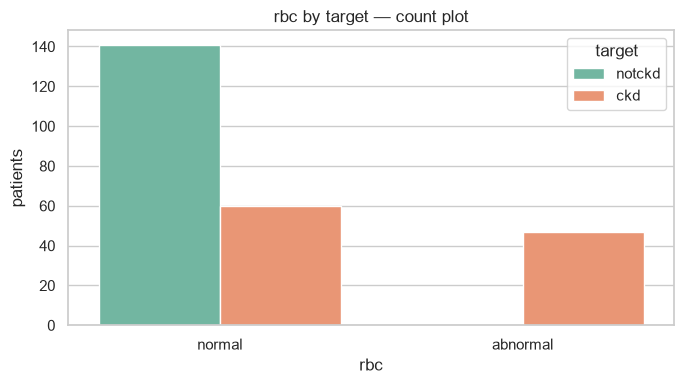

In [19]:
plot_count("rbc")

### `pc` (categorical) vs `classification` — count plot

**What the plot says:** all **76 `abnormal` pus‑cell cases are CKD (100 %)**; `normal` is 54% not‑CKD / 46 % CKD. **16 % missing**.

**Why a count plot:** a binary variable against the target shows the clean split at a glance, and pairs with the missing‑value flag.

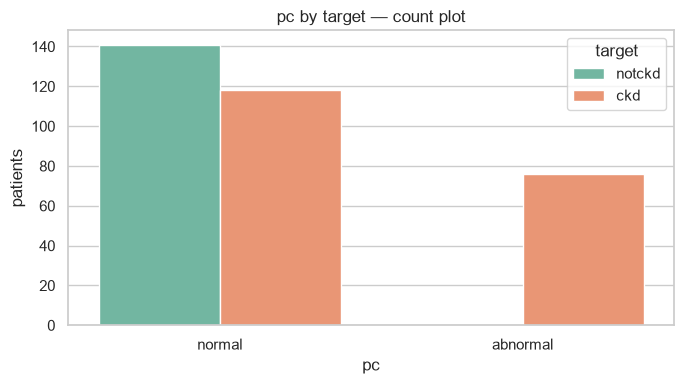

In [20]:
plot_count("pc")

### `pcc` (categorical) vs `classification` — count plot

**What the plot says:** all **42 `present` pus‑cell‑clump cases are CKD (100 %)**; `notpresent` is 59 % CKD / 41 % not‑CKD.

**Why a count plot:** low‑cardinality categorical vs target → grouped counts; the positive level is an almost perfect separator (validate it on a hold‑out split).

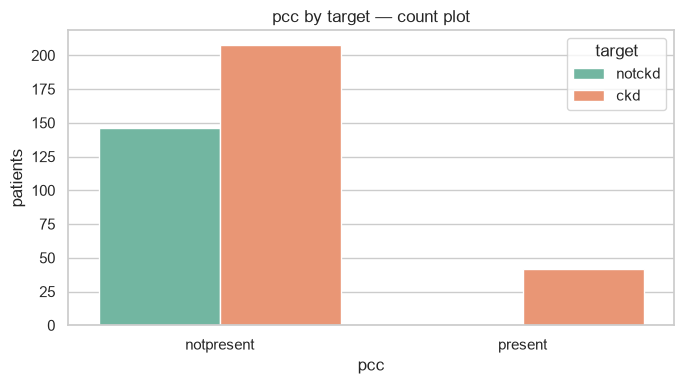

In [21]:
plot_count("pcc")

### `ba` (categorical) vs `classification` — count plot

**What the plot says:** all **22 `present` bacteria cases are CKD (100 %)**; `notpresent` is 61 % CKD / 39 % not‑CKD.

**Why a count plot:** a rare positive level that is CKD‑exclusive — the count plot makes both the rarity and the purity obvious.

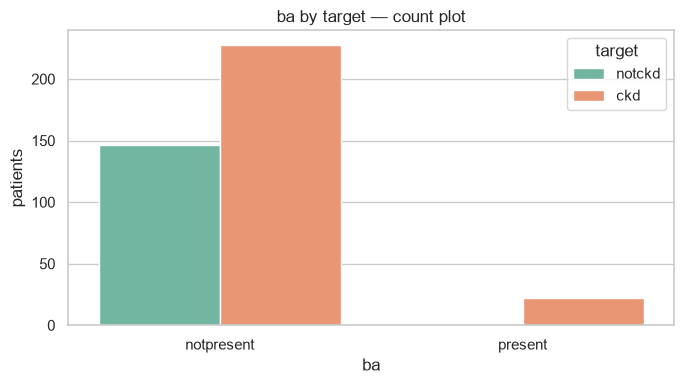

In [22]:
plot_count("ba")

### `htn` (categorical) vs `classification` — count plot

**What the plot says:** **every hypertensive patient is CKD (147/147, 100 %)**; among non‑hypertensives, 59 % are not‑CKD.

**Why a count plot:** binary clinical flag vs binary target → grouped counts; hypertension is strongly CKD‑linked (watch for leakage / selection bias).

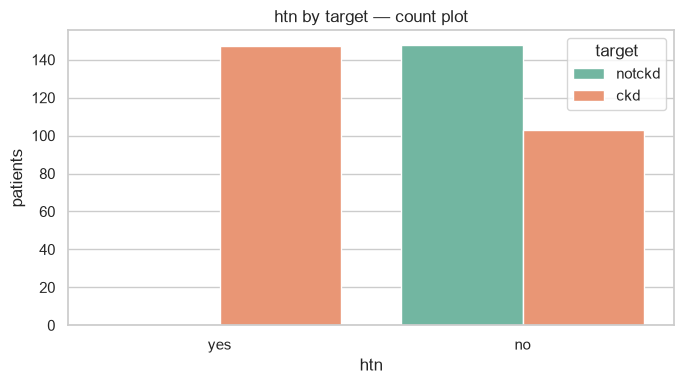

In [23]:
plot_count("htn")

### `dm` (categorical) vs `classification` — count plot

**What the plot says:** **every diabetic patient is CKD (137/137, 100 %)**; non‑diabetics are 57 % not‑CKD / 43 % CKD.

**Why a count plot:** binary flag vs target; diabetes is a known CKD driver, so the association is clinically plausible but near‑separating.

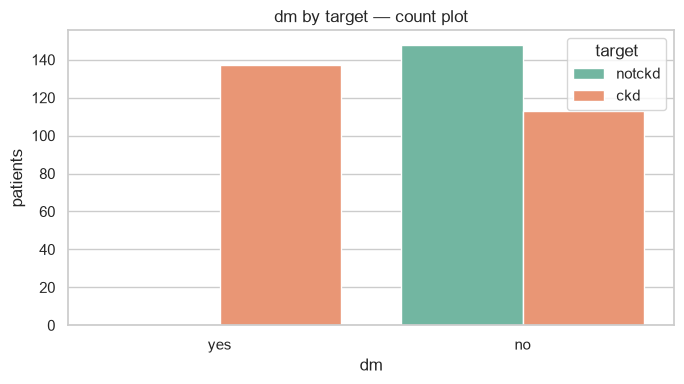

In [24]:
plot_count("dm")

### `cad` (categorical) vs `classification` — count plot

**What the plot says:** all **34 `yes` coronary‑artery‑disease cases are CKD (100 %)**; `no` is 59 % CKD / 41 % not‑CKD.

**Why a count plot:** a rare positive class that is perfectly CKD — grouped counts highlight it; check that this is not a dataset artifact.

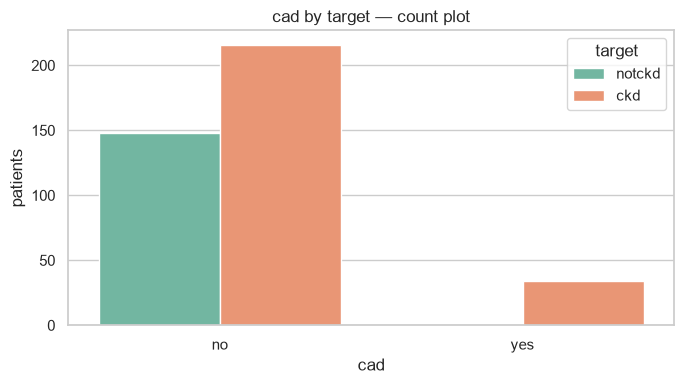

In [25]:
plot_count("cad")

### `appet` (categorical) vs `classification` — count plot

**What the plot says:** all **82 `poor` appetite cases are CKD (100 %)**; `good` is 53 % CKD / 47 % not‑CKD.

**Why a count plot:** binary symptom vs target → grouped bars; poor appetite is CKD‑exclusive in this sample.

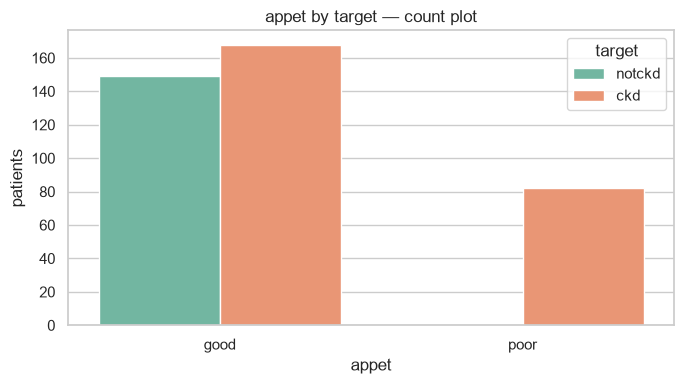

In [26]:
plot_count("appet")

### `pe` (categorical) vs `classification` — count plot

**What the plot says:** all **76 `yes` pedal‑edema cases are CKD (100 %)**; `no` is 54 % CKD / 46 % not‑CKD.

**Why a count plot:** binary sign vs target → a grouped count plot; edema is a strong CKD indicator here.

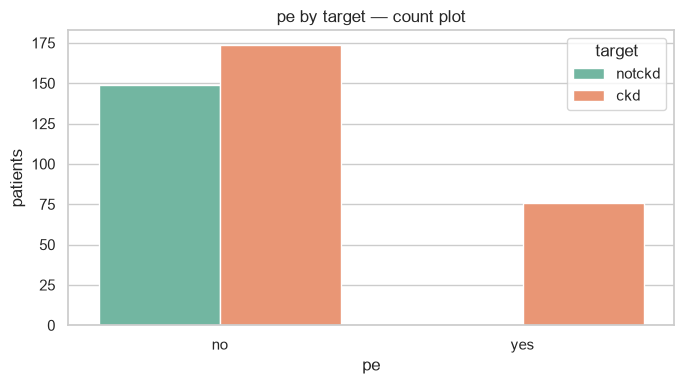

In [27]:
plot_count("pe")

### `ane` (categorical) vs `classification` — count plot

**What the plot says:** all **60 `yes` anaemia cases are CKD (100 %)**; `no` is 56 % CKD / 44 % not‑CKD.

**Why a count plot:** binary sign vs target → grouped counts; anaemia is CKD‑linked and consistent with the low hemo/pcv signal.

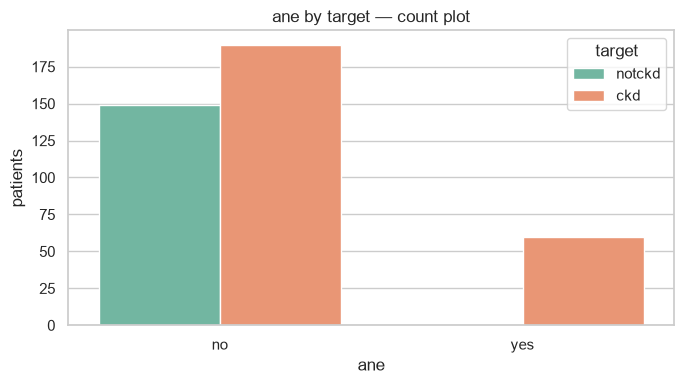

In [28]:
plot_count("ane")

## 4. Categorical association heatmaps

### Heatmap — categorical levels vs target

**What the plot says:** every "positive" clinical flag (`htn=yes`, `dm=yes`, `cad=yes`, `pe=yes`, `ane=yes`, `appet=poor`, `pcc=present`, `ba=present`, `rbc=abnormal`, `pc=abnormal`) is **100 % CKD**, while the "normal/absent" levels hover near the 60/40 base rate.

**Why a heatmap:** a row‑normalised cross‑tab puts every categorical level against the target in one view, making near‑separators and class skew immediately obvious.

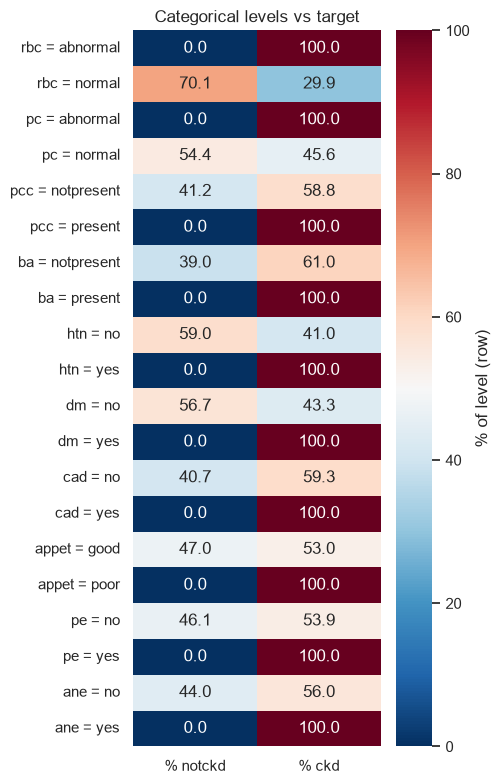

,% notckd,% ckd
rbc = abnormal,0.000000,100.000000
rbc = normal,70.149254,29.850746
pc = abnormal,0.000000,100.000000
pc = normal,54.440154,45.559846
pcc = notpresent,41.242938,58.757062
pcc = present,0.000000,100.000000
ba = notpresent,39.037433,60.962567
ba = present,0.000000,100.000000
htn = no,58.964143,41.035857
htn = yes,0.000000,100.000000


In [29]:
rows, labels = [], []
for c in CAT_COLS:
    ct = pd.crosstab(clean[c], clean[TARGET], normalize="index").reindex(columns=ORDER).mul(100)
    for level, row in ct.iterrows():
        rows.append(row.values); labels.append(f"{c} = {level}")
level_target = pd.DataFrame(rows, index=labels, columns=[f"% {t}" for t in ORDER])
fig, ax = plt.subplots(figsize=(5, 8))
sns.heatmap(level_target, annot=True, fmt=".1f", cmap="RdBu_r", vmin=0, vmax=100,
            cbar_kws={"label": "% of level (row)"}, ax=ax)
ax.set_title("Categorical levels vs target"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()
level_target

### Heatmap — Cramér's V between categorical features and target

**What the plot says:** most clinical flags show strong association with the target, and many are also strongly associated with each other (they describe the same clinical picture).

**Why a heatmap:** Cramér's V is the categorical analogue of correlation, so one matrix reveals redundancy / multicollinearity among the binary flags as well as their link to the target.

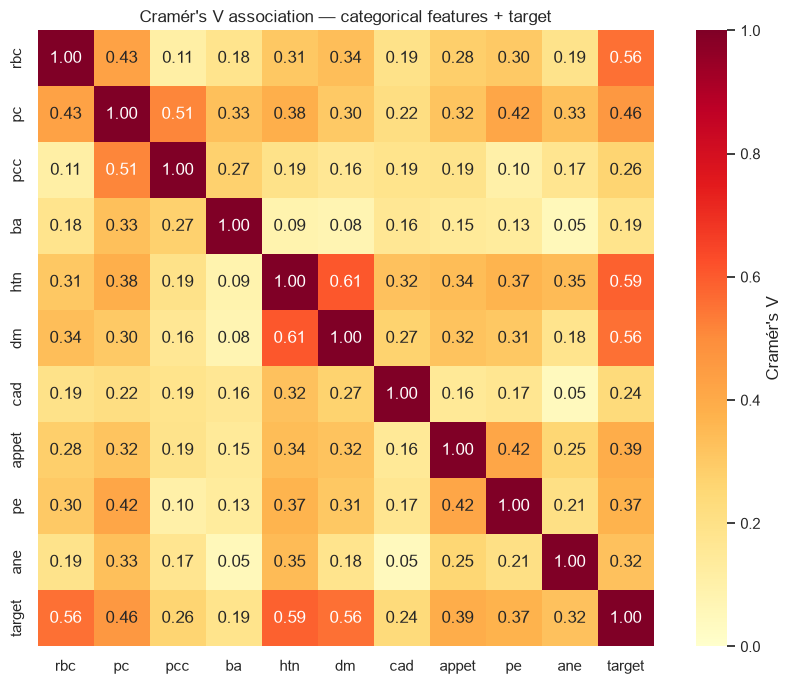

,rbc,pc,pcc,ba,htn,dm,cad,appet,pe,ane,target
rbc,1.00,0.43,0.11,0.18,0.31,0.34,0.19,0.28,0.30,0.19,0.56
pc,0.43,1.00,0.51,0.33,0.38,0.30,0.22,0.32,0.42,0.33,0.46
pcc,0.11,0.51,1.00,0.27,0.19,0.16,0.19,0.19,0.10,0.17,0.26
ba,0.18,0.33,0.27,1.00,0.09,0.08,0.16,0.15,0.13,0.05,0.19
htn,0.31,0.38,0.19,0.09,1.00,0.61,0.32,0.34,0.37,0.35,0.59
dm,0.34,0.30,0.16,0.08,0.61,1.00,0.27,0.32,0.31,0.18,0.56
cad,0.19,0.22,0.19,0.16,0.32,0.27,1.00,0.16,0.17,0.05,0.24
appet,0.28,0.32,0.19,0.15,0.34,0.32,0.16,1.00,0.42,0.25,0.39
pe,0.30,0.42,0.10,0.13,0.37,0.31,0.17,0.42,1.00,0.21,0.37
ane,0.19,0.33,0.17,0.05,0.35,0.18,0.05,0.25,0.21,1.00,0.32


In [30]:
cols = CAT_COLS + [TARGET]
v_mat = pd.DataFrame(index=cols, columns=cols, dtype=float)
for i in cols:
    for j in cols:
        v_mat.loc[i, j] = 1.0 if i == j else cramers_v(clean[i], clean[j])

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(v_mat.astype(float), annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1,
            square=True, cbar_kws={"label": "Cramér's V"}, ax=ax)
ax.set_title("Cramér's V association — categorical features + target"); plt.tight_layout(); plt.show()
v_mat.astype(float).round(2)

## 5. Feature–target summary

In [31]:
# Numeric summary
num_rows = []
for c in NUM_COLS:
    med = clean.groupby(TARGET)[c].median().reindex(ORDER)
    mean = clean.groupby(TARGET)[c].mean().reindex(ORDER)
    num_rows.append({
        "feature": c,
        "plot": PLOT_FOR[c],
        "notckd_median": round(med["notckd"], 3),
        "ckd_median": round(med["ckd"], 3),
        "median_diff": round(med["ckd"] - med["notckd"], 3),
        "notckd_mean": round(mean["notckd"], 3),
        "ckd_mean": round(mean["ckd"], 3),
        "null_%": round(clean[c].isna().mean() * 100, 1),
    })
num_summary = pd.DataFrame(num_rows).set_index("feature")
num_summary

# Categorical summary
cat_rows = []
for c in CAT_COLS:
    ct = pd.crosstab(clean[c], clean[TARGET], normalize="index").reindex(columns=ORDER)
    hi = ct["ckd"].idxmax()
    cat_rows.append({
        "feature": c,
        "level_most_linked_to_ckd": hi,
        "ckd_%_at_that_level": round(ct.loc[hi, "ckd"] * 100, 1),
        "n_at_that_level": int(clean[c].value_counts().get(hi, 0)),
        "null_%": round(clean[c].isna().mean() * 100, 1),
    })
cat_summary = pd.DataFrame(cat_rows).set_index("feature")
cat_summary

,level_most_linked_to_ckd,ckd_%_at_that_level,n_at_that_level,null_%
feature,,,,
rbc,abnormal,100.0,47,38.0
pc,abnormal,100.0,76,16.2
pcc,present,100.0,42,1.0
ba,present,100.0,22,1.0
htn,yes,100.0,147,0.5
dm,yes,100.0,137,0.5
cad,yes,100.0,34,0.5
appet,poor,100.0,82,0.2
pe,yes,100.0,76,0.2


## 6. Takeaways for modeling

- **Strongest numeric signals:** `hemo`, `pcv`, `rc` (lower in CKD), `sg`/`al` (bar‑level shift); `sc`, `bu`, `bgr` also separate but are skewed and need scaling or tree models.
- **Near‑perfect categorical separators:** every positive clinical flag (`htn`, `dm`, `cad`, `pe`, `ane`, `appet=poor`, `pcc`, `ba`, `rbc`, `pc`) is 100 % CKD here. **Validate on a hold‑out split** — these can inflate scores and may reflect selection bias.
- **Missingness is informative (MNAR):** `rbc` 38 %, `rc` 33 %, `wc` 26 %, `pot` 22 %, `sod` 22 % → add `*_was_missing` flags (especially `rbc`, `pc`) instead of relying on mode fills alone.
- **Multicollinearity:** `hemo` / `pcv` / `rc` are strongly inter‑correlated → keep one or regularise / use dimensionality reduction.
- **Data errors:** `sod = 4.5`, `pot = 47` are almost certainly typos → fix or cap before modeling.
- **Class imbalance (62.5 / 37.5):** use a stratified split and class weights / resampling.
- **Drop `id`** — it is a sequential identifier with no signal.